# FedVocabHAR WISDM Phase 1A

## Confirmation efficient registry queries with oracle pure candidates

This notebook tests the revised paper's central mechanism before local discovery and continual integration are added.

It asks one controlled question:

> At matched registry safety, can agreement guided entry selection confirm and promote global activities with fewer semantic queries than simpler policies?

The experiment deliberately constructs **oracle-pure local candidates**, but hides their activity identities from every query policy. A label becomes available only when a policy spends one semantic confirmation through the logged oracle. This isolates query allocation and registry behavior from novelty-detection and clustering errors.

The first comparison includes random selection, entropy-only selection, one query per suspected global class, and FedVocabHAR. It evaluates synchronous and staggered arrivals over paired seeds and saves complete registry and policy audit logs.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


In [5]:
from dataclasses import dataclass, asdict
from pathlib import Path
from itertools import combinations
from collections import defaultdict
import copy, hashlib, json, math, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import wilcoxon

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project: str = '/content/drive/MyDrive/FedVocabHAR'
    seed: int = 42
    development_subjects: tuple = tuple(range(1635,1642))
    engineering_subjects: tuple = tuple(range(1643,1651))
    development_activities: tuple = ('F','G','H','I','K')
    engineering_activities: tuple = ('L','M','O','P','Q','S')
    fragments_per_client_activity: int = 2
    max_windows_per_fragment: int = 40
    pca_components: int = 24
    target_pair_precision: float = 0.90
    fallback_negative_fpr: float = 0.01
    inheritance_margin: float = 0.05
    promotion_quorum: int = 2
    registry_precision_gate: float = 0.90
    seeds: tuple = (11,23,37,51,79)
    arrival_modes: tuple = ('synchronous','staggered')
    confirmations_per_activity: tuple = (0.25,0.5,1.0,2.0)

CFG=Config()
PROJECT=Path(CFG.project)
P0=PROJECT/'artifacts'/'phase0'
P0B=PROJECT/'artifacts'/'phase0b'
OUT=PROJECT/'artifacts'/'phase1a'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz'
MODEL=P0B/'contrastive_encoder.pt'
assert CACHE.exists(), f'Missing Phase Zero cache: {CACHE}'
assert MODEL.exists(), f'Missing Phase Zero-B encoder: {MODEL}'

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE)
print('project:',PROJECT)
print(json.dumps(asdict(CFG),indent=2))


device: cuda
project: /content/drive/MyDrive/FedVocabHAR
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "development_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "engineering_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647,
    1648,
    1649,
    1650
  ],
  "development_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "engineering_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "fragments_per_client_activity": 2,
  "max_windows_per_fragment": 40,
  "pca_components": 24,
  "target_pair_precision": 0.9,
  "fallback_negative_fpr": 0.01,
  "inheritance_margin": 0.05,
  "promotion_quorum": 2,
  "registry_precision_gate": 0.9,
  "seeds": [
    11,
    23,
    37,
    51,
    79
  ],
  "arrival_modes": [
    "synchronous",
    "staggered"
  ],
  "confirmations_per_activity": [
    0.25,
    0.5,
    1.0,
    2.0
  ]
}


## Load the fixed Phase Zero cache and encoder

The representation is fixed before Phase 1A. Development activities may train and calibrate the compatibility model. Engineering activity names remain private to the confirmation oracle and evaluator.


In [6]:
d=np.load(CACHE)
x=d['x'].astype(np.float32)
subjects=d['subject'].astype(int)
activities=d['activity'].astype(str)
positions=d['position'].astype(np.float32)

class Encoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,z):
        h=self.body(z).squeeze(-1)
        return F.normalize(self.project(h),dim=1)

# Phase Zero-B created this checkpoint inside the same FedVocabHAR project.
# PyTorch 2.6+ defaults to weights_only=True, which rejects the stored NumPy
# normalization arrays. Explicitly permit the trusted project checkpoint.
try:
    checkpoint=torch.load(MODEL,map_location='cpu',weights_only=False)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint=torch.load(MODEL,map_location='cpu')
dim=int(checkpoint['config']['embedding_dim'])
encoder=Encoder(dim).to(DEVICE)
encoder.load_state_dict(checkpoint['state_dict'])
encoder.eval()
channel_mean=np.asarray(checkpoint['channel_mean'],dtype=np.float32)
channel_std=np.asarray(checkpoint['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std

emb=[]
with torch.no_grad():
    for start in range(0,len(xn),512):
        emb.append(encoder(torch.from_numpy(xn[start:start+512]).to(DEVICE)).cpu().numpy())
emb=np.concatenate(emb).astype(np.float32)
print('windows:',x.shape,'embeddings:',emb.shape)
print(pd.crosstab(subjects,activities).to_string())


windows: (19704, 3, 128) embeddings: (19704, 96)
col_0    A    B    C    D    E    F    G    H    I    K    L    M    O    P    Q    R    S
row_0                                                                                     
1635    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1636    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1637   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1638   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1639   138  138  138  138  138  138  138  138  138  138    0  138  138  138  138  138  138
1640   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1641    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1643    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1644    55   55   55   55   55   55   55 

In [7]:
def signal_features(a,fs=20.0):
    mag=np.linalg.norm(a,axis=1,keepdims=True)
    z=np.concatenate([a,mag],axis=1)
    centered=z-z.mean(2,keepdims=True)
    std=centered.std(2)+1e-8
    feats=[]
    funcs=[lambda q:q.mean(2),lambda q:q.std(2),lambda q:np.median(q,2),
           lambda q:np.quantile(q,.10,axis=2),lambda q:np.quantile(q,.25,axis=2),
           lambda q:np.quantile(q,.75,axis=2),lambda q:np.quantile(q,.90,axis=2),
           lambda q:np.sqrt((q*q).mean(2)),lambda q:np.abs(q).mean(2),
           lambda q:np.sqrt((np.diff(q,axis=2)**2).mean(2))]
    feats += [fn(z) for fn in funcs]
    feats.append((np.diff(np.signbit(centered),axis=2)!=0).mean(2))
    feats.append((centered[:,:,:-1]*centered[:,:,1:]).mean(2)/(std*std))
    fft=np.abs(np.fft.rfft(centered,axis=2))**2
    freqs=np.fft.rfftfreq(z.shape[2],1/fs); fft[:,:,0]=0
    total=fft.sum(2)+1e-8; prob=fft/total[:,:,None]
    feats += [(fft*freqs).sum(2)/total,freqs[np.argmax(fft,axis=2)],-(prob*np.log(prob+1e-12)).sum(2)]
    for lo,hi in [(0,.5),(.5,1.5),(1.5,3),(3,5),(5,10.1)]:
        band=(freqs>=lo)&(freqs<hi); feats.append(fft[:,:,band].sum(2)/total)
    feats.append(np.stack([
        (centered[:,0]*centered[:,1]).mean(1)/(std[:,0]*std[:,1]),
        (centered[:,0]*centered[:,2]).mean(1)/(std[:,0]*std[:,2]),
        (centered[:,1]*centered[:,2]).mean(1)/(std[:,1]*std[:,2])],1))
    return np.nan_to_num(np.concatenate(feats,1).astype(np.float32))

sf=signal_features(x)
dev_window=np.isin(subjects,CFG.development_subjects) & np.isin(activities,CFG.development_activities)
sf_pipe=Pipeline([('scale',StandardScaler()),('pca',PCA(CFG.pca_components,random_state=CFG.seed))])
em_pipe=Pipeline([('scale',StandardScaler()),('pca',PCA(CFG.pca_components,random_state=CFG.seed))])
sf_red=sf_pipe.fit(sf[dev_window]).transform(sf).astype(np.float32)
em_red=em_pipe.fit(emb[dev_window]).transform(emb).astype(np.float32)
print('reduced features:',sf_red.shape,em_red.shape)


reduced features: (19704, 24) (19704, 24)


## Construct oracle pure local candidates

Candidates are contiguous fragments within a client and activity episode. The activity field is removed from the public table immediately after construction. Only the private oracle and evaluator retain it.


In [8]:
def evenly_limit(idx,limit):
    if len(idx)<=limit: return idx
    take=np.linspace(0,len(idx)-1,limit).round().astype(int)
    return idx[take]

def build_candidates(subject_set,activity_set,prefix):
    rows=[]; descriptors=[]; stat_centers=[]; emb_centers=[]; private={}
    cid=0
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)<CFG.fragments_per_client_activity: continue
            idx=idx[np.argsort(positions[idx])]
            for fragment,part in enumerate(np.array_split(idx,CFG.fragments_per_client_activity)):
                part=evenly_limit(part,CFG.max_windows_per_fragment)
                if len(part)==0: continue
                smean,sstd=sf_red[part].mean(0),sf_red[part].std(0)
                emean,estd=em_red[part].mean(0),em_red[part].std(0)
                descriptor=np.concatenate([smean,sstd,emean,estd]).astype(np.float32)
                candidate_id=f'{prefix}_{cid:04d}'
                rows.append({'candidate_id':candidate_id,'subject':int(subject),'fragment':int(fragment),
                             'support':int(len(part)),'time_center':float(positions[part].mean())})
                descriptors.append(descriptor); stat_centers.append(smean); emb_centers.append(emean)
                private[candidate_id]=str(activity); cid+=1
    public=pd.DataFrame(rows)
    forbidden={'activity','true_activity','label','y'} & set(public.columns)
    assert not forbidden, f'Hidden-label leakage in public table: {forbidden}'
    return public,np.stack(descriptors),np.stack(stat_centers),np.stack(emb_centers),private

dev_public,dev_desc,dev_stat,dev_emb,dev_oracle=build_candidates(
    CFG.development_subjects,CFG.development_activities,'dev')
eng_public,eng_desc,eng_stat,eng_emb,eng_oracle=build_candidates(
    CFG.engineering_subjects,CFG.engineering_activities,'eng')
print('development candidates:',len(dev_public),'engineering candidates:',len(eng_public))
display(dev_public.head())
assert set(eng_public.candidate_id)==set(eng_oracle)


development candidates: 70 engineering candidates: 96


,candidate_id,subject,fragment,support,time_center
0,dev_0000,1635,0,28,0.248490
1,dev_0001,1635,1,27,0.754674
2,dev_0002,1635,0,28,0.248490
3,dev_0003,1635,1,27,0.754674
4,dev_0004,1635,0,28,0.248419


## Fit and calibrate compatibility on development activities only

The compatibility model learns from development candidates. Calibration first searches for a threshold that reaches 0.90 development pair precision with at least five selected pairs. If none exists, it falls back to a one-percent negative-tail threshold and records the fallback explicitly.


In [9]:
def pair_feature(a,b):
    na=np.linalg.norm(a)+1e-8; nb=np.linalg.norm(b)+1e-8
    return np.concatenate([np.abs(a-b),a*b,[float(a@b/(na*nb)),float(na),float(nb)]])

def pair_rows(public,desc,oracle,allowed_subjects):
    ids=public.candidate_id.tolist(); id_to_i={v:i for i,v in enumerate(ids)}
    out=[]
    for ia,ib in combinations(range(len(ids)),2):
        ra,rb=public.iloc[ia],public.iloc[ib]
        if ra.subject==rb.subject: continue
        if int(ra.subject) not in allowed_subjects or int(rb.subject) not in allowed_subjects: continue
        out.append((pair_feature(desc[ia],desc[ib]),int(oracle[ids[ia]]==oracle[ids[ib]])))
    return np.stack([q[0] for q in out]),np.asarray([q[1] for q in out])

train_subjects=set(CFG.development_subjects[:-2]); cal_subjects=set(CFG.development_subjects[-2:])
Xtr,ytr=pair_rows(dev_public,dev_desc,dev_oracle,train_subjects)
Xcal,ycal=pair_rows(dev_public,dev_desc,dev_oracle,cal_subjects)
matcher=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=3000,class_weight='balanced',random_state=CFG.seed))])
matcher.fit(Xtr,ytr)
cal_score=matcher.predict_proba(Xcal)[:,1]

def choose_threshold(y,score,target,min_selected=5,fallback_fpr=.01):
    candidates=[]
    for threshold in np.unique(score):
        selected=score>=threshold
        if selected.sum()<min_selected: continue
        precision=float(y[selected].mean())
        recall=float((selected & (y==1)).sum()/max(1,(y==1).sum()))
        if precision>=target: candidates.append((recall,-threshold,threshold,precision,int(selected.sum())))
    if candidates:
        _,_,threshold,precision,n=max(candidates)
        return float(threshold),{'status':'target_precision','precision':precision,'selected':n}
    negatives=score[y==0]
    threshold=float(np.quantile(negatives,1-fallback_fpr))
    selected=score>=threshold
    return threshold,{'status':'negative_tail_fallback','precision':float(y[selected].mean()) if selected.any() else None,
                      'selected':int(selected.sum()),'fallback_fpr':fallback_fpr}

PAIR_THRESHOLD,threshold_record=choose_threshold(ycal,cal_score,CFG.target_pair_precision,
                                                  fallback_fpr=CFG.fallback_negative_fpr)
calibration={'auroc':float(roc_auc_score(ycal,cal_score)),'average_precision':float(average_precision_score(ycal,cal_score)),
             'threshold':PAIR_THRESHOLD,**threshold_record}
print(json.dumps(calibration,indent=2))


{
  "auroc": 0.49124999999999996,
  "average_precision": 0.20950857461971548,
  "threshold": 0.9999999999999362,
  "status": "negative_tail_fallback",
  "precision": 0.0,
  "selected": 1,
  "fallback_fpr": 0.01
}


In [10]:
def cosine_matrix(a):
    z=a/(np.linalg.norm(a,axis=1,keepdims=True)+1e-8)
    return np.clip((z@z.T+1)/2,0,1)

def compatibility_matrix(public,desc):
    n=len(public); P=np.eye(n,dtype=np.float32)
    for i,j in combinations(range(n),2):
        q=float(matcher.predict_proba(pair_feature(desc[i],desc[j])[None])[0,1])
        P[i,j]=P[j,i]=q
    return P

P=compatibility_matrix(eng_public,eng_desc)
P_stat=cosine_matrix(eng_stat); P_emb=cosine_matrix(eng_emb)
np.fill_diagonal(P,0); np.fill_diagonal(P_stat,0); np.fill_diagonal(P_emb,0)

ids=eng_public.candidate_id.tolist(); hidden=np.array([eng_oracle[q] for q in ids])
pair_y=[]; pair_s=[]
for i,j in combinations(range(len(ids)),2):
    if eng_public.iloc[i].subject==eng_public.iloc[j].subject: continue
    pair_y.append(int(hidden[i]==hidden[j])); pair_s.append(float(P[i,j]))
engineering_pair_diagnostic={'auroc':float(roc_auc_score(pair_y,pair_s)),
                             'average_precision':float(average_precision_score(pair_y,pair_s)),
                             'tpr':float(np.mean(np.asarray(pair_s)[np.asarray(pair_y)==1]>=PAIR_THRESHOLD)),
                             'fpr':float(np.mean(np.asarray(pair_s)[np.asarray(pair_y)==0]>=PAIR_THRESHOLD))}
print(json.dumps(engineering_pair_diagnostic,indent=2))


{
  "auroc": 0.665760080073696,
  "average_precision": 0.2356294288693847,
  "tpr": 0.6309523809523809,
  "fpr": 0.3952380952380952
}


## Auditable query policies and confirmation oracle

The selection functions receive only public candidate metadata, compatibility matrices, current query history, and public arrival times. They never receive the private activity dictionary. The oracle is the only function that returns an engineering activity identity.


In [11]:
POLICIES=('random','entropy','suspected_global','fedvocabhar')
PUBLIC_POLICY_COLUMNS=('candidate_id','subject','fragment','support','time_center','arrival_round')

def norm(v):
    v=np.asarray(v,dtype=float)
    lo,hi=np.nanmin(v),np.nanmax(v)
    return np.zeros_like(v) if hi-lo<1e-12 else (v-lo)/(hi-lo)

def binary_entropy(q):
    q=np.clip(q,1e-6,1-1e-6)
    return -(q*np.log(q)+(1-q)*np.log(1-q))

def policy_components(eligible,queried):
    eligible=np.asarray(eligible,dtype=int)
    entropy=[]; disagreement=[]; merge_risk=[]; split_risk=[]; coverage=[]; redundancy=[]
    for i in eligible:
        peers=np.asarray([j for j in eligible if j!=i and eng_public.iloc[j].subject!=eng_public.iloc[i].subject],dtype=int)
        q=P[i,peers] if len(peers) else np.asarray([0.0])
        entropy.append(float(binary_entropy(q).mean()))
        disagreement.append(float(np.abs(P_stat[i,peers]-P_emb[i,peers]).mean()) if len(peers) else 0.0)
        merge_risk.append(float((q*(1-q)*(q>=.25)).sum()))
        split_risk.append(float(np.mean((q>=.35)&(q<PAIR_THRESHOLD))))
        coverage.append(float(1+(q>=PAIR_THRESHOLD).sum()))
        redundancy.append(float(P[i,list(queried)].max()) if queried else 0.0)
    comp=pd.DataFrame({'candidate_index':eligible,'entropy':norm(entropy),'disagreement':norm(disagreement),
                       'merge_risk':norm(merge_risk),'split_risk':norm(split_risk),
                       'coverage_gain':norm(coverage),'redundancy':norm(redundancy)})
    comp['fedvocabhar_score']=(.20*comp.entropy+.15*comp.disagreement+.20*comp.merge_risk+
                               .10*comp.split_risk+.35*comp.coverage_gain-.25*comp.redundancy)
    return comp

def connected_components(nodes,threshold):
    remaining=set(nodes); groups=[]
    while remaining:
        root=remaining.pop(); group={root}; frontier=[root]
        while frontier:
            i=frontier.pop()
            add={j for j in list(remaining) if P[i,j]>=threshold}
            remaining-=add; group|=add; frontier.extend(add)
        groups.append(sorted(group))
    return groups

def select_candidate(policy,eligible,queried,rng):
    comp=policy_components(eligible,queried)
    if policy=='random':
        chosen=int(rng.choice(eligible))
    elif policy=='entropy':
        chosen=int(comp.sort_values(['entropy','coverage_gain'],ascending=False).iloc[0].candidate_index)
    elif policy=='suspected_global':
        groups=connected_components(eligible,PAIR_THRESHOLD)
        group=max(groups,key=lambda g:(len(g),-min(g)))
        chosen=int(max(group,key=lambda i:(P[i,group].sum(),-i)))
    elif policy=='fedvocabhar':
        jitter=rng.normal(0,1e-9,len(comp))
        chosen=int(comp.iloc[np.argmax(comp.fedvocabhar_score.to_numpy()+jitter)].candidate_index)
    else: raise ValueError(policy)
    return chosen,comp

def confirmation_oracle(candidate_index,oracle_log,step):
    candidate_id=eng_public.iloc[candidate_index].candidate_id
    label=eng_oracle[candidate_id]
    oracle_log.append({'step':step,'candidate_id':candidate_id,'returned_label':label})
    return label

def recompute_assignments(confirmed_seeds):
    assignments={i:label for i,label in confirmed_seeds.items()}
    conflicts=set()
    labels=sorted(set(confirmed_seeds.values()))
    for j in range(len(eng_public)):
        if j in confirmed_seeds: continue
        scores=[]
        for label in labels:
            seeds=[i for i,y in confirmed_seeds.items() if y==label and eng_public.iloc[i].subject!=eng_public.iloc[j].subject]
            scores.append((max([P[j,i] for i in seeds],default=0.0),label))
        scores=sorted(scores,reverse=True)
        if not scores or scores[0][0]<PAIR_THRESHOLD: continue
        if len(scores)>1 and scores[0][0]-scores[1][0]<CFG.inheritance_margin:
            conflicts.add(j); continue
        assignments[j]=scores[0][1]
    return assignments,conflicts


In [12]:
def evaluate_state(assignments,confirmed_seeds,query_count):
    records=[]
    for i,pred in assignments.items():
        records.append({'i':i,'predicted':pred,'true':eng_oracle[eng_public.iloc[i].candidate_id],
                        'subject':int(eng_public.iloc[i].subject),'direct':i in confirmed_seeds})
    frame=pd.DataFrame(records)
    if frame.empty:
        return {'registry_precision':np.nan,'report_coverage':0.0,'activity_coverage':0.0,
                'integrated_classes':0,'confirmations_per_integrated_class':np.inf,
                'false_merge_classes':0,'duplicate_confirmations':0,'correct_assignments':0,'assigned':0}
    precision=float((frame.predicted==frame.true).mean())
    promoted=[]; false_merge=0
    for label,g in frame.groupby('predicted'):
        purity=float((g.true==label).mean()); clients=g.subject.nunique()
        if clients>=CFG.promotion_quorum and purity>=CFG.registry_precision_gate: promoted.append(label)
        if g.true.nunique()>1: false_merge+=1
    direct_labels=[eng_oracle[eng_public.iloc[i].candidate_id] for i in confirmed_seeds]
    duplicate=max(0,len(direct_labels)-len(set(direct_labels)))
    integrated=len(set(promoted))
    return {'registry_precision':precision,'report_coverage':len(frame)/len(eng_public),
            'activity_coverage':len(set(promoted))/len(CFG.engineering_activities),
            'integrated_classes':integrated,
            'confirmations_per_integrated_class':query_count/integrated if integrated else np.inf,
            'false_merge_classes':false_merge,'duplicate_confirmations':duplicate,
            'correct_assignments':int((frame.predicted==frame.true).sum()),'assigned':len(frame)}

def run_policy(policy,budget,scenario_seed,arrival_mode):
    rng=np.random.default_rng(scenario_seed)
    public=eng_public.copy()[list(PUBLIC_POLICY_COLUMNS[:-1])]
    if arrival_mode=='synchronous': public['arrival_round']=0
    else: public['arrival_round']=rng.integers(0,max(1,budget),len(public))
    assert tuple(public.columns)==PUBLIC_POLICY_COLUMNS
    confirmed_seeds={}; queried=[]; oracle_log=[]; event_log=[]; score_log=[]
    assignments={}; conflicts=set(); clock=0
    while len(queried)<budget:
        eligible=[i for i in range(len(public)) if i not in confirmed_seeds and
                  i not in assignments and int(public.iloc[i].arrival_round)<=clock]
        if not eligible:
            future=public.loc[[i not in confirmed_seeds and i not in assignments for i in range(len(public))],'arrival_round']
            if len(future)==0: break
            clock=max(clock+1,int(future.min())); continue
        chosen,components=select_candidate(policy,eligible,queried,rng)
        components=components.copy(); components['policy']=policy; components['step']=len(queried)+1
        components['candidate_id']=components.candidate_index.map(lambda i: public.iloc[int(i)].candidate_id)
        components['chosen']=components.candidate_index.eq(chosen); components['scenario_seed']=scenario_seed
        components['arrival_mode']=arrival_mode; components['budget']=budget
        score_log.append(components)
        label=confirmation_oracle(chosen,oracle_log,len(queried)+1)
        previous_assignments=dict(assignments)
        confirmed_seeds[chosen]=label; queried.append(chosen)
        assignments,conflicts=recompute_assignments(confirmed_seeds)
        base={'step':len(queried),'clock':clock,'policy':policy,'budget':budget,
                          'scenario_seed':scenario_seed,'arrival_mode':arrival_mode,
                          'assigned_reports':len(assignments),'conflicts':len(conflicts)}
        event_log.append({**base,'action':'semantic_confirmation','candidate_id':public.iloc[chosen].candidate_id,
                          'subject':int(public.iloc[chosen].subject),'registry_label':label})
        for i,new_label in assignments.items():
            old_label=previous_assignments.get(i)
            if old_label==new_label: continue
            action='direct_assignment' if i==chosen else ('inherited_assignment' if old_label is None else 'assignment_changed')
            event_log.append({**base,'action':action,'candidate_id':public.iloc[i].candidate_id,
                              'subject':int(public.iloc[i].subject),'registry_label':new_label})
        for i,old_label in previous_assignments.items():
            if i not in assignments:
                event_log.append({**base,'action':'assignment_revoked','candidate_id':public.iloc[i].candidate_id,
                                  'subject':int(public.iloc[i].subject),'registry_label':old_label})
        for i in conflicts:
            event_log.append({**base,'action':'conflict_deferred','candidate_id':public.iloc[i].candidate_id,
                              'subject':int(public.iloc[i].subject),'registry_label':None})
        for registry_label in sorted(set(assignments.values())):
            members=[i for i,y in assignments.items() if y==registry_label]
            if eng_public.iloc[members].subject.nunique()>=CFG.promotion_quorum:
                event_log.append({**base,'action':'promotion_eligible','candidate_id':None,'subject':None,
                                  'registry_label':registry_label})
        clock+=1
    metrics=evaluate_state(assignments,confirmed_seeds,len(queried))
    metrics.update({'policy':policy,'budget':budget,'scenario_seed':scenario_seed,'arrival_mode':arrival_mode,
                    'queries_used':len(queried),'conflicts':len(conflicts),'threshold':PAIR_THRESHOLD})
    assigned_rows=[]
    for i,label in assignments.items():
        assigned_rows.append({'policy':policy,'budget':budget,'scenario_seed':scenario_seed,
                              'arrival_mode':arrival_mode,'candidate_id':public.iloc[i].candidate_id,
                              'subject':int(public.iloc[i].subject),'assigned_label':label,
                              'true_label':eng_oracle[public.iloc[i].candidate_id],
                              'source':'direct' if i in confirmed_seeds else 'inherited'})
    return metrics,event_log,score_log,assigned_rows,oracle_log


## Run paired policy comparisons

Budgets are expressed as confirmations per true novel activity. Every policy receives the same candidate set, compatibility evidence, arrival realization, and total query budget for a paired scenario.


In [13]:
summary=[]; events=[]; scores=[]; assignments=[]; oracle_audit=[]
n_activities=len(CFG.engineering_activities)
for per_activity in CFG.confirmations_per_activity:
    budget=max(1,int(math.ceil(per_activity*n_activities)))
    for arrival_mode in CFG.arrival_modes:
        for scenario_seed in CFG.seeds:
            for policy in POLICIES:
                m,e,s,a,o=run_policy(policy,budget,scenario_seed,arrival_mode)
                m['confirmations_per_activity_budget']=per_activity
                summary.append(m); events.extend(e); scores.extend(s); assignments.extend(a)
                oracle_audit.extend([{**q,'policy':policy,'budget':budget,'scenario_seed':scenario_seed,
                                      'arrival_mode':arrival_mode} for q in o])

summary=pd.DataFrame(summary)
events=pd.DataFrame(events)
policy_scores=pd.concat(scores,ignore_index=True) if scores else pd.DataFrame()
assignment_log=pd.DataFrame(assignments)
oracle_audit=pd.DataFrame(oracle_audit)

summary.to_csv(OUT/'phase1a_summary.csv',index=False)
events.to_csv(OUT/'phase1a_registry_events.csv',index=False)
policy_scores.to_csv(OUT/'phase1a_policy_scores.csv',index=False)
assignment_log.to_csv(OUT/'phase1a_assignments.csv',index=False)
oracle_audit.to_csv(OUT/'phase1a_oracle_audit.csv',index=False)
display(summary.groupby(['confirmations_per_activity_budget','arrival_mode','policy'])[
    ['registry_precision','report_coverage','activity_coverage','confirmations_per_integrated_class',
     'false_merge_classes','duplicate_confirmations']].mean().round(3))


registry_precision  \
confirmations_per_activity_budget arrival_mode policy                                 
0.25                              staggered    entropy                        1.000   
                                               fedvocabhar                    0.275   
                                               random                         0.474   
                                               suspected_global               0.414   
                                  synchronous  entropy                        1.000   
                                               fedvocabhar                    0.276   
                                               random                         0.403   
                                               suspected_global               0.246   
0.50                              staggered    entropy                        0.900   
                                               fedvocabhar                    0.486   
                                               random                         0.389   
                                               suspected_global               0.507   
                                  synchronous  entropy                        1.000   
                                               fedvocabhar                    0.378   
                                               random                         0.287   
                                               suspected_global               0.750   
1.00                              staggered    entropy                        0.690   
                                               fedvocabhar                    0.504   
                                               random                         0.714   
                                               suspected_global               0.670   
                                  synchronous  entropy                        0.667   
                                               fedvocabhar                    0.846   
                                               random                         0.628   
                                               suspected_global               0.500   
2.00                              staggered    entropy                        0.663   
                                               fedvocabhar                    1.000   
                                               random                         0.985   
                                               suspected_global               0.971   
                                  synchronous  entropy                        0.571   
                                               fedvocabhar                    1.000   
                                               random                         1.000   
                                               suspected_global               1.000   

                                                                 report_coverage  \
confirmations_per_activity_budget arrival_mode policy                              
0.25                              staggered    entropy                     0.021   
                                               fedvocabhar                 0.412   
                                               random                      0.360   
                                               suspected_global            0.419   
                                  synchronous  entropy                     0.021   
                                               fedvocabhar                 0.604   
                                               random                      0.323   
                                               suspected_global            0.677   
0.50                              staggered    entropy                     0.038   
                                               fedvocabhar                 0.256   
                                               random                      0.406   
              

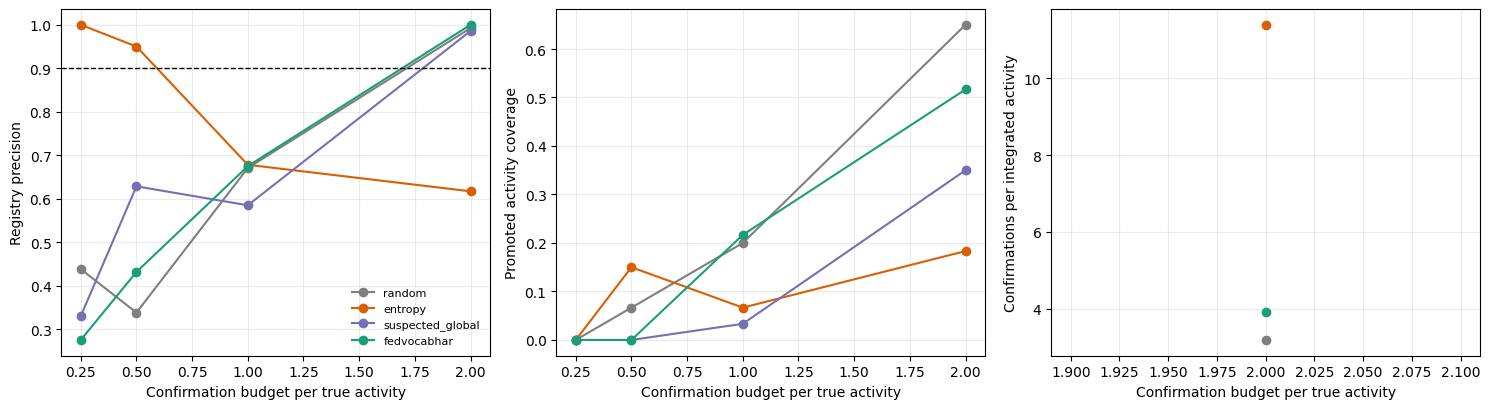

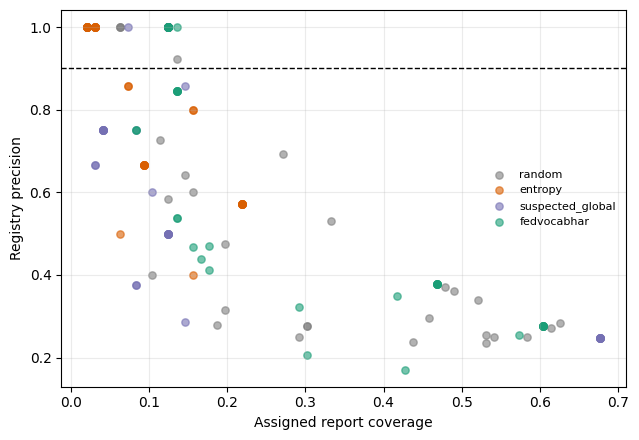

In [14]:
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
colors={'random':'#7f7f7f','entropy':'#d95f02','suspected_global':'#7570b3','fedvocabhar':'#1b9e77'}
agg=summary.groupby(['confirmations_per_activity_budget','policy'],as_index=False).agg(
    registry_precision=('registry_precision','mean'),report_coverage=('report_coverage','mean'),
    activity_coverage=('activity_coverage','mean'),ce=('confirmations_per_integrated_class',lambda z:np.mean(np.where(np.isfinite(z),z,np.nan))))
for policy in POLICIES:
    q=agg[agg.policy==policy]
    axes[0].plot(q.confirmations_per_activity_budget,q.registry_precision,'o-',label=policy,color=colors[policy])
    axes[1].plot(q.confirmations_per_activity_budget,q.activity_coverage,'o-',label=policy,color=colors[policy])
    axes[2].plot(q.confirmations_per_activity_budget,q.ce,'o-',label=policy,color=colors[policy])
axes[0].axhline(CFG.registry_precision_gate,color='black',ls='--',lw=1)
axes[0].set_ylabel('Registry precision'); axes[1].set_ylabel('Promoted activity coverage')
axes[2].set_ylabel('Confirmations per integrated activity')
for ax in axes:
    ax.set_xlabel('Confirmation budget per true activity'); ax.grid(alpha=.25)
axes[0].legend(frameon=False,fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'phase1a_policy_comparison.png',dpi=180,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(6.5,4.5))
for policy in POLICIES:
    q=summary[summary.policy==policy]
    ax.scatter(q.report_coverage,q.registry_precision,s=28,alpha=.6,label=policy,color=colors[policy])
ax.axhline(CFG.registry_precision_gate,color='black',ls='--',lw=1)
ax.set_xlabel('Assigned report coverage'); ax.set_ylabel('Registry precision'); ax.grid(alpha=.25)
ax.legend(frameon=False,fontsize=8); fig.tight_layout()
fig.savefig(OUT/'phase1a_risk_coverage.png',dpi=180,bbox_inches='tight'); plt.show()


## Feasibility decision

The primary operating point is one confirmation per true engineering activity. Gate G2 uses paired scenario results and requires FedVocabHAR to improve confirmation efficiency over both random and entropy-only selection. Infinite confirmation-efficiency values indicate that no class was safely integrated and are treated as failures rather than removed silently.


In [15]:
primary=summary[np.isclose(summary.confirmations_per_activity_budget,1.0)].copy()

def finite_penalty(values):
    values=np.asarray(values,dtype=float)
    finite=values[np.isfinite(values)]
    penalty=(finite.max()*2 if len(finite) else 1e6)
    return np.where(np.isfinite(values),values,penalty)

def paired_test(a,b,metric,alternative='less'):
    key=['scenario_seed','arrival_mode','budget']
    left=a[key+[metric]].rename(columns={metric:'left'})
    right=b[key+[metric]].rename(columns={metric:'right'})
    q=left.merge(right,on=key)
    x,y=finite_penalty(q.left),finite_penalty(q.right)
    if len(q)<2 or np.allclose(x,y): return {'n':len(q),'pvalue':1.0,'median_difference':float(np.median(x-y))}
    test=wilcoxon(x,y,alternative=alternative,zero_method='zsplit')
    return {'n':len(q),'pvalue':float(test.pvalue),'median_difference':float(np.median(x-y))}

fed=primary[primary.policy=='fedvocabhar']
random_base=primary[primary.policy=='random']
entropy_base=primary[primary.policy=='entropy']
test_random=paired_test(fed,random_base,'confirmations_per_integrated_class','less')
test_entropy=paired_test(fed,entropy_base,'confirmations_per_integrated_class','less')

mean_precision=float(fed.registry_precision.mean())
mean_coverage=float(fed.activity_coverage.mean())
gates={
    'G1_registry_safety':bool(mean_precision>=CFG.registry_precision_gate),
    'G2_query_efficiency_vs_random':bool(test_random['median_difference']<0 and test_random['pvalue']<.05),
    'G2_query_efficiency_vs_entropy':bool(test_entropy['median_difference']<0 and test_entropy['pvalue']<.05),
    'G3_useful_coverage':bool(mean_coverage>=.50),
    'G4_stability':bool(all(fed.groupby('arrival_mode').registry_precision.mean()>=CFG.registry_precision_gate)),
    'G5_auditability':bool(len(events)>0 and len(policy_scores)>0 and len(oracle_audit)>0)
}
decision={
    'phase':'Phase 1A',
    'calibration':calibration,
    'engineering_pair_diagnostic':engineering_pair_diagnostic,
    'primary_operating_point':{'confirmations_per_activity':1.0,'fedvocabhar_mean_registry_precision':mean_precision,
                               'fedvocabhar_mean_activity_coverage':mean_coverage,
                               'paired_vs_random':test_random,'paired_vs_entropy':test_entropy},
    'gates':gates,
    'proceed_to_phase1b':bool(all(gates.values())),
    'interpretation':('Proceed to confirmed-class integration.' if all(gates.values()) else
                      'Do not start end-to-end integration claims. Inspect failed gates and revise the query or inheritance rule.'),
    'config':asdict(CFG),
    'label_access_rule':'Engineering activity identities were available only to confirmation_oracle and evaluation.'
}
(OUT/'phase1a_decision.json').write_text(json.dumps(decision,indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 1A",
  "calibration": {
    "auroc": 0.49124999999999996,
    "average_precision": 0.20950857461971548,
    "threshold": 0.9999999999999362,
    "status": "negative_tail_fallback",
    "precision": 0.0,
    "selected": 1,
    "fallback_fpr": 0.01
  },
  "engineering_pair_diagnostic": {
    "auroc": 0.665760080073696,
    "average_precision": 0.2356294288693847,
    "tpr": 0.6309523809523809,
    "fpr": 0.3952380952380952
  },
  "primary_operating_point": {
    "confirmations_per_activity": 1.0,
    "fedvocabhar_mean_registry_precision": 0.6748747575953458,
    "fedvocabhar_mean_activity_coverage": 0.21666666666666665,
    "paired_vs_random": {
      "n": 10,
      "pvalue": 0.328125,
      "median_difference": 0.0
    },
    "paired_vs_entropy": {
      "n": 10,
      "pvalue": 0.046875,
      "median_difference": -7.5
    }
  },
  "gates": {
    "G1_registry_safety": false,
    "G2_query_efficiency_vs_random": false,
    "G2_query_efficiency_vs_entropy": true,
    

In [16]:
report=f"""# FedVocabHAR Phase 1A Decision Report

## Decision

**Proceed to Phase 1B:** {decision['proceed_to_phase1b']}

{decision['interpretation']}

## Primary operating point

- Confirmation budget: 1.0 per true novel activity
- Mean FedVocabHAR registry precision: {mean_precision:.3f}
- Mean FedVocabHAR promoted activity coverage: {mean_coverage:.3f}
- Paired confirmation-efficiency test versus random: p={test_random['pvalue']:.4f}, median difference={test_random['median_difference']:.3f}
- Paired confirmation-efficiency test versus entropy: p={test_entropy['pvalue']:.4f}, median difference={test_entropy['median_difference']:.3f}

## Gates

"""
for name,value in gates.items(): report+=f'- {name}: **{value}**\n'
report+="""
## Interpretation boundary

This is an engineering feasibility study with oracle-pure local candidates. It evaluates semantic-query allocation and registry inheritance, not novelty detection, local clustering, or continual classifier integration. WISDM has already been inspected during Phase Zero and is not an untouched confirmatory dataset.
"""
(OUT/'FedVocabHAR_Phase1A_Decision_Report.md').write_text(report)
print(report)
print('saved outputs to',OUT)


# FedVocabHAR Phase 1A Decision Report

## Decision

**Proceed to Phase 1B:** False

Do not start end-to-end integration claims. Inspect failed gates and revise the query or inheritance rule.

## Primary operating point

- Confirmation budget: 1.0 per true novel activity
- Mean FedVocabHAR registry precision: 0.675
- Mean FedVocabHAR promoted activity coverage: 0.217
- Paired confirmation-efficiency test versus random: p=0.3281, median difference=0.000
- Paired confirmation-efficiency test versus entropy: p=0.0469, median difference=-7.500

## Gates

- G1_registry_safety: **False**
- G2_query_efficiency_vs_random: **False**
- G2_query_efficiency_vs_entropy: **True**
- G3_useful_coverage: **False**
- G4_stability: **False**
- G5_auditability: **True**

## Interpretation boundary

This is an engineering feasibility study with oracle-pure local candidates. It evaluates semantic-query allocation and registry inheritance, not novelty detection, local clustering, or continual classifier inte

## Reading the outcome

- **All gates pass:** freeze the Phase 1A query and inheritance policy, then implement Phase 1B with oracle-confirmed identities and lightweight continual integration.
- **Safety passes but efficiency fails:** semantic confirmation remains necessary, but agreement-guided prioritization is not yet a contribution. Inspect duplicate queries and utility ablations.
- **Safety fails:** tighten inheritance, add re-query or adjudication, and do not treat confirmation of one entry as permission to label its entire neighborhood.
- **Coverage fails:** the threshold is too conservative or the representation cannot support useful propagation. Report the risk-coverage boundary rather than lowering the safety target silently.

After development on WISDM, freeze the selected policy and repeat the protocol on RealWorld HAR before making a confirmatory claim.
